# Laboratorio de regresión logística

|                |                  |
:----------------|------------------|
| **Nombre**     | Omar Mendoza     |
| **Fecha**      | 10/10/2026       |
| **Expediente** | 757806           |

In machine learning, Support Vector Machines (SVM) are supervised learning models with associated learning algorithms that analyze data used for classification and regression analysis. It is mostly used in classification problems. In this algorithm, each data item is plotted as a point in p-dimensional space (where p is the number of features), with the value of each feature being the value of a particular coordinate. Then, classification is performed by finding the hyper-plane that best differentiates the two classes (or more if we have a multi class problem):

$$ f(x) = w^T \varphi(x) + b $$

where $\varphi: X \rightarrow F $ is a function that makes each input point $x$ correspond to a point in F, where F is a Hilbert space.

In addition to performing linear classification, SVMs can efficiently perform a non-linear classification, implicitly mapping their inputs into high-dimensional feature spaces (more specifically using the kernel trick, like the RBF funcion). 

[1]

OLS utilizes the squared residuals to fit the parameters. Large residuals caused by outliers may worsen the accuracy significantly.

Support Vectors use piecewise linear functions to counter this, in which a hyperparameter  $\epsilon$ called the margin lets errors that are less or equal to it be 0, and error larger than it be $e - \epsilon$. 

The problem to solve is:

\begin{split}
        \min_{w, b, \xi, \xi^*} \mathcal{P}_\epsilon(w, b, \xi) &= \frac{1}{2} w^T w + c \sum_{k=1}^{N} \xi_k \\
        \text{s.t. } & y_k [w^T \varphi(x_k) - b] \geq 1- \xi_k,\ \ k = 1, ..., N \\
        & \xi_k \geq 0,\ \ k = 1, ..., N
\end{split}


The most important question that arises when using a SVM is how to choose the correct hyperplane. Consider the following scenarios:

### Scenario 1

In this scenario there are three hyperplanes called A, B, and C. Now, the problem is to identify the hyperplane which best differentiates the stars and the circles.

<center><img src="https://media.geeksforgeeks.org/wp-content/uploads/SVM_21-2.png" alt="what image shows"></center>

In this case, hyperplane B separates the stars and the circle betters, hence it is the correct hyperplane.


### Scenario 2

Now take another scenario where all three hyperplanes are segregating classes well. The question that arises is how to choose the best hyperplane in this situation.

<center><img src="https://media.geeksforgeeks.org/wp-content/uploads/SVM_4-2.png" alt="what image shows"></center>

In such scenarios, we calculate the margin (which is the distance between nearest data point and the hyperplane). The hyperplane with the largest margin will be considered as the correct hyperplane to classify the dataset.

Here C has the largest margin. Hence, it is considered as the best hyperplane.


### Kernels
Knowing 
$$ w = \sum_{k=1}^{N} \alpha_k y_k \varphi(x_k) $$

And
$$ y_{pred} = w^T \varphi(x) + b $$

Then 
$$ y_{pred} = (\sum_{k=1}^{N} \alpha_k y_k \varphi(x_k))^T \varphi(x) + b $$

Where $\varphi$ is a function that makes each input in $x$ correspond to a point in $F$ (a Hilbert space). This can be seen as processing and transforming the input featuers to keep the model's convexity. [2]

This also allows us to transform the inputs into another space where they might be more easily classified.

<center><img src=https://miro.medium.com/max/838/1*gXvhD4IomaC9Jb37tzDUVg.png alt="what image shows"></center>

## ROC and AUC

A ROC (Receiver Operating Characteristic) is a graph that shows how the classification model performs at the classification thresholds. 

ROC curves typically feature true positive rate on the Y axis, and false positive rate on the X axis. This means that the top left corner of the plot is the “ideal” point - a false positive rate of zero, and a true positive rate of one. This is not very realistic, but it does mean that a larger area under the curve (AUC) is usually better. [3]

True Positive Rate is a synonym for Recall and defined as:
$$ TPR = \frac{TP}{TP + FN} $$

False Positive Rate is a synonym for Specificity and defined as:

$$ FPR = \frac{FP}{FP + TN} $$

ROC curves are typically used in binary classification to study the output of a classifier. In order to extend ROC curve and ROC area to multi-label classification, it is necessary to binarize the output. One ROC curve can be drawn per label, but one can also draw a ROC curve by considering each element of the label indicator matrix as a binary prediction (micro-averaging).

E.g. If you lower a classification threshold, more items would be classified as positive, increasing False Positives and True Positives.

AUC stands for Area under the ROC.

## Ejercicio 1

- Utiliza el dataset `Iris`, modela con SVC y haz Cross-Validation de diferentes kernels ('linear', 'poly', 'rbf', 'sigmoid').
- Modela con LogisticRegression.
- El método de Cross-Validation es K-Folds con $k=10$.
- Utiliza el AUC como métrico de Cross-Validation.
- Compara resultados.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

In [2]:
iris = load_iris()
X = iris.data
y = iris.target

print(X.shape)
print(iris.target_names)
print(np.bincount(y))

(150, 4)
['setosa' 'versicolor' 'virginica']
[50 50 50]


Son 150 flores con 4 medidas cada una, largo y ancho del sepalo y del petalo, y 3 especies con 50 flores cada una, esta balanceado

In [3]:
# probability=True para que el SVC tambien saque predict_proba igual que la logistica

modelos = {
    "SVC linear": Pipeline([("esc", StandardScaler()), ("modelo", SVC(kernel="linear", probability=True, random_state=42))]),
    "SVC poly": Pipeline([("esc", StandardScaler()), ("modelo", SVC(kernel="poly", probability=True, random_state=42))]),
    "SVC rbf": Pipeline([("esc", StandardScaler()), ("modelo", SVC(kernel="rbf", probability=True, random_state=42))]),
    "SVC sigmoid": Pipeline([("esc", StandardScaler()), ("modelo", SVC(kernel="sigmoid", probability=True, random_state=42))]),
    "LogisticRegression": Pipeline([("esc", StandardScaler()), ("modelo", LogisticRegression())]),
}

In [4]:
# shuffle porque el iris viene ordenado por especie

kf = KFold(n_splits=10, shuffle=True, random_state=42)
auc_iris = {}

for nombre, modelo in modelos.items():
    aucs = []
    for train_idx, test_idx in kf.split(X):
        modelo.fit(X[train_idx], y[train_idx])
        proba = modelo.predict_proba(X[test_idx])
        aucs.append(roc_auc_score(y[test_idx], proba, multi_class="ovr"))
    auc_iris[nombre] = aucs

auc_iris = pd.DataFrame(auc_iris)
auc_iris.agg(["mean", "std", "min"]).T.round(4)

,mean,std,min
SVC linear,1.0000,0.0000,1.0000
SVC poly,1.0000,0.0000,1.0000
SVC rbf,0.9959,0.0130,0.9588
SVC sigmoid,0.9819,0.0351,0.9032
LogisticRegression,0.9967,0.0087,0.9725


Se entrenan los 5 modelos en los mismos 10 folds. Como son 3 especies el AUC se saca con ovr, un AUC por especie contra las otras dos y luego se promedian

El shuffle es porque el iris viene ordenado por especie, sin revolver el primer fold serian puras setosas y el AUC ni se podria calcular

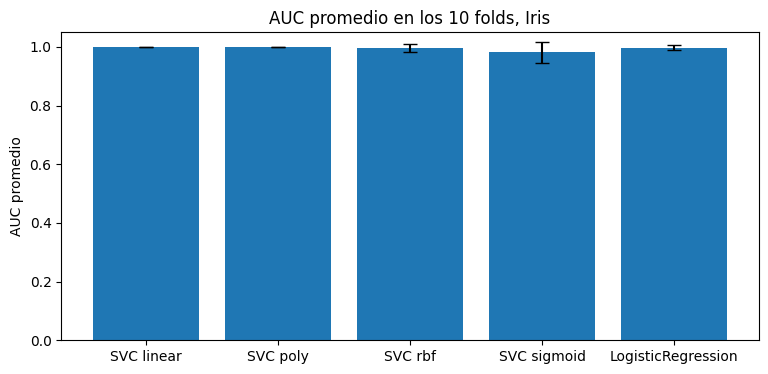

In [5]:
resumen = auc_iris.agg(["mean", "std"]).T

plt.figure(figsize=(9, 4))
plt.bar(resumen.index, resumen["mean"], yerr=resumen["std"], capsize=5)
plt.ylim(0, 1.05)
plt.ylabel("AUC promedio")
plt.title("AUC promedio en los 10 folds, Iris")
plt.show()

Todos salen arriba de 0.98, el iris es muy facil de separar. El linear y el poly sacaron AUC de 1 en los 10 folds, separaron perfecto las 3 especies. La logistica y el rbf quedan casi igual con 0.997 y 0.996, nomas fallaron un poquito en uno o dos folds

El peor es el sigmoid con 0.982 y es el que mas varia, bajo hasta 0.903 en un fold. Ese kernel no es muy estable y por eso casi no se usa

Con datos asi de faciles no hay mucha diferencia, cualquiera sirve y lo mejor seria quedarse con el mas sencillo, el linear o la logistica

## Ejercicio 2
- Repite el ejercicio 1 con el dataset `Default`. Utiliza `default` como target.

In [6]:
datos = pd.read_csv("Default.csv")
datos["student"] = (datos["student"] == "Yes").astype(int)

X = datos[["balance", "income", "student"]].values
y = (datos["default"] == "Yes").astype(int).values

print(X.shape)
print(np.bincount(y))

(10000, 3)
[9667  333]


Son 10000 personas con balance, income y student ya en 0 y 1. Solo 333 dejaron de pagar, el 3.3 por ciento, entonces cada fold de 1000 trae entre 24 y 43 de esos

In [7]:
auc_default = {}

for nombre, modelo in modelos.items():
    aucs = []
    for train_idx, test_idx in kf.split(X):
        modelo.fit(X[train_idx], y[train_idx])
        proba = modelo.predict_proba(X[test_idx])[:, 1]
        aucs.append(roc_auc_score(y[test_idx], proba))
    auc_default[nombre] = aucs

auc_default = pd.DataFrame(auc_default)
auc_default.agg(["mean", "std", "min"]).T.round(4)

,mean,std,min
SVC linear,0.9221,0.0161,0.8929
SVC poly,0.8750,0.0460,0.7756
SVC rbf,0.8394,0.0395,0.7568
SVC sigmoid,0.7373,0.0285,0.6763
LogisticRegression,0.9491,0.0180,0.9193


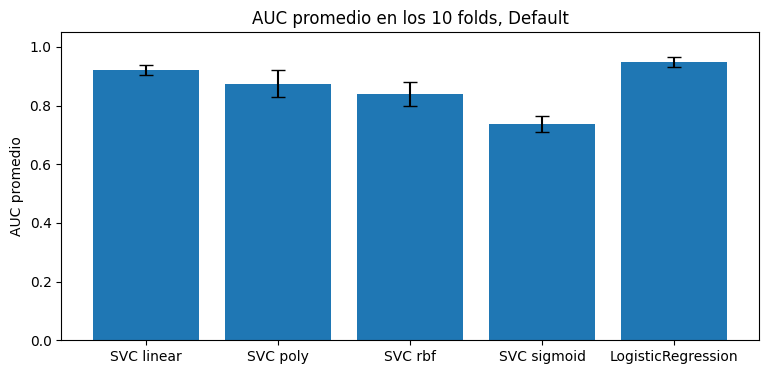

In [8]:
resumen = auc_default.agg(["mean", "std"]).T

plt.figure(figsize=(9, 4))
plt.bar(resumen.index, resumen["mean"], yerr=resumen["std"], capsize=5)
plt.ylim(0, 1.05)
plt.ylabel("AUC promedio")
plt.title("AUC promedio en los 10 folds, Default")
plt.show()

Aqui si hay diferencia. La mejor es la logistica con 0.949, despues el SVC linear con 0.922 y los demas kernels van bajando, poly 0.875, rbf 0.839 y el sigmoid 0.737 que otra vez es el peor

Pasa lo contrario de lo que uno pensaria, los kernels mas complicados salen peor. En el lab pasado se vio que el default depende casi todo del balance y de forma lineal, entonces la curva logistica le queda bien y meterle kernels nomas mete ruido. Ademas hay muy pocos que si dejaron de pagar, como 33 por fold, y al SVC le cuesta mas acomodar la frontera con tan pocos de una clase

La logistica tambien es la mas estable, su peor fold fue 0.919 que es mas alto que el promedio del poly, el rbf y el sigmoid

Comparando los dos ejercicios, en el iris todos empataban porque las especies se separan facil, pero en el Default con datos desbalanceados y una relacion lineal la logistica es la que gana

# Addendum

Métricos disponibles para clasificación:
- ‘accuracy’
- ‘balanced_accuracy’
- ‘top_k_accuracy’
- ‘average_precision’
- ‘neg_brier_score’
- ‘f1’
- ‘f1_micro’
- ‘f1_macro’
- ‘f1_weighted’
- ‘f1_samples’
- ‘neg_log_loss’
- ‘precision’ etc.
- ‘recall’ etc.
- ‘jaccard’ etc.
- ‘roc_auc’
- ‘roc_auc_ovr’
- ‘roc_auc_ovo’
- ‘roc_auc_ovr_weighted’
- ‘roc_auc_ovo_weighted’
- ‘d2_log_loss_score’

# References

[1] Shigeo Abe.Support Vector Machines for Pattern Classification,2Ed.Springer-Verlag London,2010. ISBN978-1-84996-097-7. URLhttps://www.springer.com/gp/book/9781849960977.

[2] Johan A K Suykens, Tony Van Gestel, Jos De Brabanter, BartDe Moor, and Joos Vandewalle.Least Squares Support VectorMachines. World Scientific,2002. ISBN9789812381514. URLhttps://www.worldscientific.com/worldscibooks/10.1142/5089.

[3] Bradley, A. P. (1997). The use of the area under the ROC curve in the evaluation of machine learning algorithms. Pattern recognition, 30(7), 1145-1159. URL https://www.researchgate.net/post/how_can_I_interpret_the_ROC_curve_result